# Gastrulation dynamics and mass

Load the current pretrained **20,000-step, unbalanced, multimodal** COATI model and inspect E8.5 instantaneous growth and RNA UMAP flow. Then decompose the predicted change in one cell type into incoming, outgoing and reweighting contributions.

The compact AnnData contains 35,503 paired cells, RNA PCA50, ATAC LSI14, the original RNA UMAP, numeric time and supplied cell-type labels. This notebook performs no refitting.

In [1]:
from pathlib import Path
import sys

project_dir = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "pyproject.toml").exists() and (p / "src/coati").is_dir()), None)
if project_dir is None:
    raise FileNotFoundError("Run this notebook inside a COATI checkout.")
for path in (project_dir / "src", project_dir / "examples"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from coati import downstream as ds
from gastrulation.nmp_pretrained import DATA_PATH, load_nmp_results, validate_nmp_inputs

%matplotlib inline
plt.rcParams.update({"font.family": "Arial", "font.size": 10})

Matplotlib is building the font cache; this may take a moment.


## Load the current pretrained result

The model is the same full-data checkpoint used by the NMP trajectory tutorial: seed 0, $C_y=0.5$, width 800, three hidden layers and 20,000 training iterations. Checksums verify the compact data, FiLM map and checkpoint before inference.

In [2]:
cells = ad.read_h5ad(DATA_PATH)
checks = validate_nmp_inputs()
results, manifest = load_nmp_results(cells, device="cpu")
result = results["unbalanced"]

model_summary = pd.DataFrame([{
    "model": "COATI unbalanced",
    "iterations": result.metadata["checkpoint_iteration"],
    "seed": manifest["assets"][result.metadata["checkpoint"]]["seed"],
    "C_y": result.metadata["cy"],
    "alpha_growth": result.metadata["config"]["alpha_growth"],
    "inputs verified": all(checks.values()),
}])
model_summary

,model,iterations,seed,C_y,alpha_growth,inputs verified
0,COATI unbalanced,20000,0,0.5,1.0,True


## E8.5 growth and flow on the existing UMAP

The left panel projects the learned RNA PCA50 velocity into the supplied RNA UMAP using a local regularized map. The right panel evaluates instantaneous $d\log w/dt$ at every observed E8.5 cell. It is neither cumulative mass nor measured proliferation, and the flow is not a scVelo splicing model.

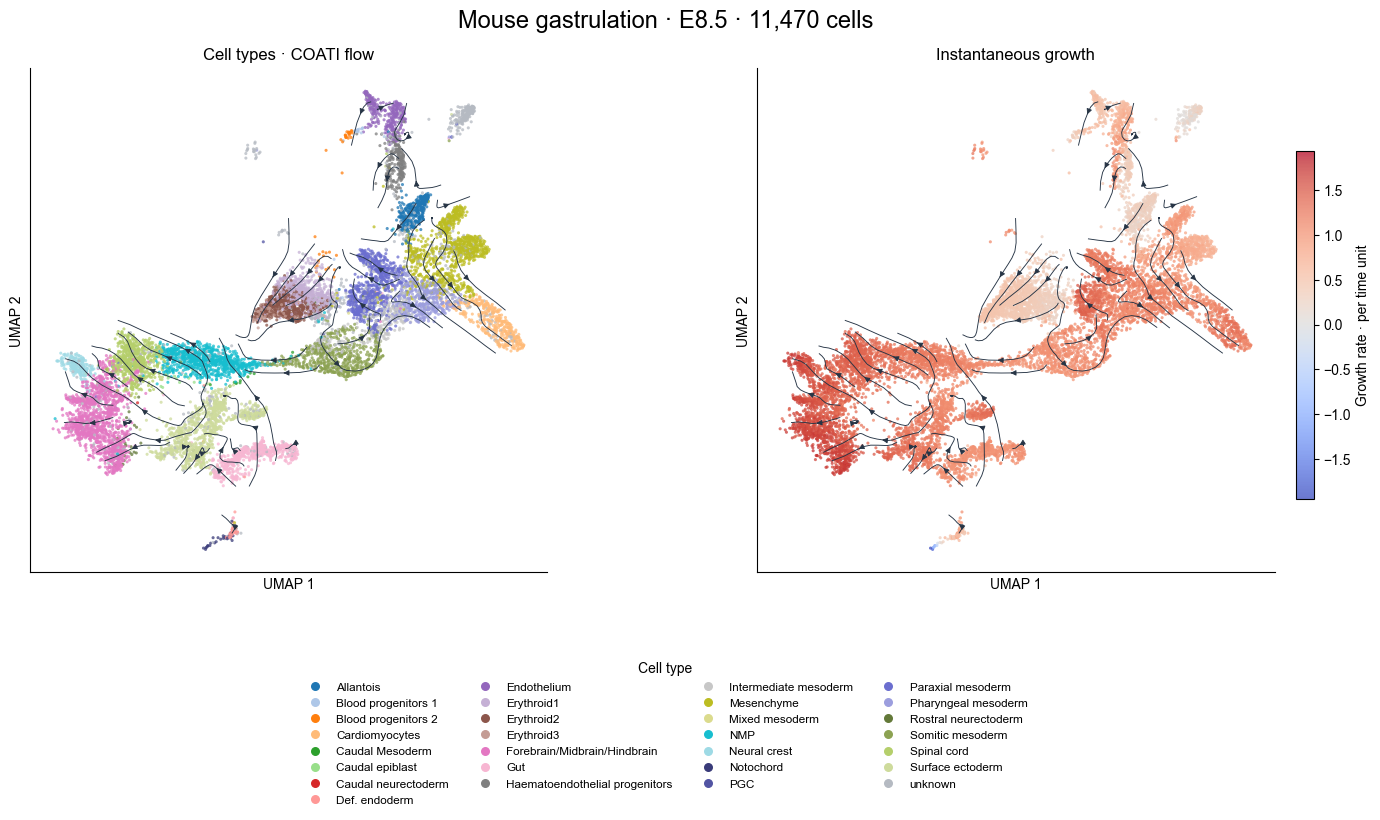

In [3]:
stage_cells = cells[cells.obs["stage"] == "E8.5"].copy()
names = stage_cells.obs["celltype"].cat.categories
colors = list(plt.get_cmap("tab20").colors) + list(plt.get_cmap("tab20b").colors)
palette = dict(zip(names, colors))
palette["unknown"] = "#b5bac2"

fig, axes = plt.subplots(1, 2, figsize=(14.5, 8.4))
result.plot_dynamics(
    stage_cells,
    use_rep="X_pca",
    axes=axes,
    labels=False,
    palette=palette,
    point_size=5,
    alpha=.75,
    density=1.3,
    linewidth=.65,
    arrow_size=.8,
    grid_size=60,
)
legend = axes[0].get_legend()
fig.legend(
    legend.legend_handles,
    [text.get_text() for text in legend.get_texts()],
    loc="lower center",
    bbox_to_anchor=(.5, .01),
    ncol=4,
    frameon=False,
    fontsize=8.5,
    title="Cell type",
    markerscale=1.3,
)
legend.remove()
fig.suptitle(f"Mouse gastrulation · E8.5 · {stage_cells.n_obs:,} cells", fontsize=17, y=.97)
axes[0].set_position([.04, .30, .40, .60])
axes[1].set_position([.52, .30, .40, .60])
fig.axes[2].set_position([.935, .36, .012, .47])
plt.show()

## Decompose one cell type over a time interval

The example follows all 9,018 E7.5 particles and examines NMP from E8.0 to E8.5. Endpoint labels are transferred from the corresponding observed RNA PCA50 cells by hard 1-NN; UMAP is not used for the calculation.

Weights are normalized across the full predicted population at each endpoint. Incoming uses later weights, outgoing uses earlier weights, and reweighting uses the mass change of particles that remain NMP:

$$\Delta p_{\mathrm{NMP}}=I_{\mathrm{NMP}}-O_{\mathrm{NMP}}+R_{\mathrm{NMP}}.$$

In [4]:
CELLTYPE = "NMP"
START_TIME, END_TIME = 1.0, 2.0

trajectory = result.predict_trajectory(times=np.linspace(0.0, 2.5, 26), raw=True)
mass = ds.decompose_mass(
    trajectory,
    cells,
    celltype=CELLTYPE,
    start_time=START_TIME,
    end_time=END_TIME,
    use_rep="X_pca",
    n_neighbors=1,
)
row = mass.summary.loc[CELLTYPE]
assert abs(row["closure_error"]) < 1e-10

print(f"Full source population: {len(mass.assignments):,} particles")
print(f"Predicted {CELLTYPE} proportion: {100 * row.start_proportion:.2f}% → {100 * row.end_proportion:.2f}%")
pd.DataFrame(
    {"Contribution (percentage points)": 100 * np.array([
        row.incoming, -row.outgoing, row.reweighting, row.net_change,
    ])},
    index=["Incoming", "Outgoing", "Reweighting", "Predicted net change"],
)

Full source population: 9,018 particles
Predicted NMP proportion: 3.57% → 7.74%


,Contribution (percentage points)
Incoming,4.731281
Outgoing,-1.012193
Reweighting,0.447255
Predicted net change,4.166343


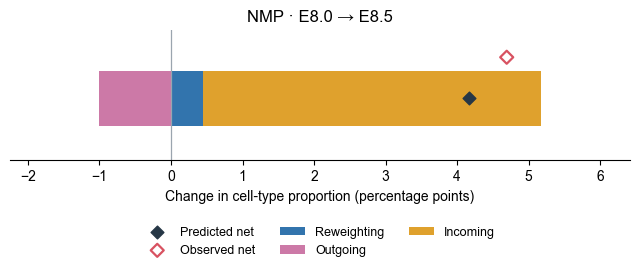

In [5]:
stage_names = {0.0: "E7.5", 1.0: "E8.0", 2.0: "E8.5", 2.5: "E8.75"}
mass.plot(
    show_observed=True,
    title=f"{CELLTYPE} · {stage_names[START_TIME]} → {stage_names[END_TIME]}",
)
plt.show()

`mass.summary` contains incoming, outgoing, reweighting and net change in relative cell-type proportions. `mass.transitions` groups endpoint label changes, while `mass.assignments` retains particle-level endpoint labels, weights and distances. The observed cross-sectional change is shown only as a reference and is not a direct transition measurement of the same cohort.